# Tool-result format vs. tokens and accuracy

**Question:** when an agent gets data back from a tool (an MCP server, a function call), does the **format of the tool result** change how many tokens it costs and how accurately the model answers questions about it?

- **Setup:** the user asks 3 questions, the assistant calls a tool (scripted), the tool returns the same 20 rows as CSV, a markdown table, compact JSON, pretty JSON, or XML. Only the model's answer is generated; no code.
- **Questions:** lookups and small counts (q1: a number from one row, q2: a name from one row, q3: count the rows with a value). Graded against the true value.
- **Model:** `qwen3:8b`, thinking off. (`qwen2.5-coder:7b` got ~8% right, and averages/rates were near 0% for both models.)
- **Controls:** same model, temperature, and system prompt on every call. 6 tasks × 5 formats × 5 runs = 150 calls.

In [1]:
import json
import html
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import HTML, Markdown

SEED = 42
RESULTS_CSV = "../data/tool_results.csv"
TASKS_DIR = Path("../tool_tasks")
MODEL = "qwen3:8b"

DATA_FORMATS = ["csv", "markdown", "json", "json_pretty", "xml"]
DATA_COLORS = {"csv": "#008300", "markdown": "#d4762c", "json": "#1d6fb8", "json_pretty": "#7fb8e6", "xml": "#4a3aa7"}
DATA_MARKERS = {"csv": "o", "markdown": "^", "json": "v", "json_pretty": "P", "xml": "s"}
QUESTIONS = ["q1", "q2", "q3"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
responses["total_tokens"] = responses["input_tokens"] + responses["output_tokens"]
responses["accuracy"] = responses["n_correct"] / 3

# one row per question, for accuracy
answers = responses.melt(id_vars=["task_id", "data_format", "run", "output_tokens"],
                         value_vars=[f"{q}_correct" for q in QUESTIONS], var_name="question", value_name="correct")
answers["question"] = answers["question"].str.removesuffix("_correct")

print(f"{len(responses)} responses, {len(answers)} answers")
print("stop reasons:", responses["stop_reason"].value_counts().to_dict())
print("replies with a readable ANSWERS line:", f"{responses['answered'].mean():.0%}")
responses.head()

150 responses, 450 answers
stop reasons: {'stop': 150}
replies with a readable ANSWERS line: 100%


,task_id,data_format,run,model,input_tokens,output_tokens,q1_answer,q2_answer,q3_answer,q1_correct,q2_correct,q3_correct,n_correct,answered,stop_reason,seconds,timestamp,total_tokens,accuracy
0,t33_objectives,json,4,qwen3:8b,1380,33,10.0,"""Nongshim RedForce Academy""",6,True,True,False,2,True,stop,1.42,2026-10-21T09:48:31+00:00,1413,0.666667
1,t36_support_vision,markdown,4,qwen3:8b,865,64,99.0,"""Los Ratones""","""2""",True,True,True,3,True,stop,1.59,2026-10-21T09:48:33+00:00,929,1.000000
2,t35_jungle_picks,markdown,5,qwen3:8b,619,58,1.0,"""Xin Zhao""",3,True,True,True,3,True,stop,1.31,2026-10-21T09:48:34+00:00,677,1.000000
3,t36_support_vision,markdown,5,qwen3:8b,865,64,99.0,"""Los Ratones""","""2""",True,True,True,3,True,stop,1.29,2026-10-21T09:48:35+00:00,929,1.000000
4,t34_mid_kda,csv,1,qwen3:8b,749,55,21.0,"""Aurora""","""2""",True,True,False,2,True,stop,1.35,2026-10-21T09:48:37+00:00,804,0.666667


In [2]:
TASK_IDS = sorted(p.name for p in TASKS_DIR.glob("t*") if p.is_dir())
EXAMPLE_TASK = "t31_side_winrate"

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

def preview(text, data_format, n=2):
    """The first n rows of a tool result."""
    if data_format == "json":
        return text[:260] + " ..."
    if data_format == "json_pretty":
        return "\n".join(text.splitlines()[:1 + 7 * n]) + "\n  ..."
    header = {"csv": 1, "markdown": 2, "xml": 1}[data_format]
    return "\n".join(text.splitlines()[:header + n]) + "\n..."

display(Markdown(f"#### `{EXAMPLE_TASK}`: the user's message"))
display(HTML(f'<pre style="white-space:pre-wrap">{html.escape(read_task_file(EXAMPLE_TASK, "questions.txt"))}</pre>'))
display(Markdown("#### The tool result, first rows in each format"))
for d in DATA_FORMATS:
    display(HTML(f'<b>{d}</b><pre style="white-space:pre-wrap; font-size:85%">'
                 f'{html.escape(preview(read_task_file(EXAMPLE_TASK, f"data_{d}.txt"), d))}</pre>'))

#### `t31_side_winrate`: the user's message

#### The tool result, first rows in each format

## 1. Input tokens by format

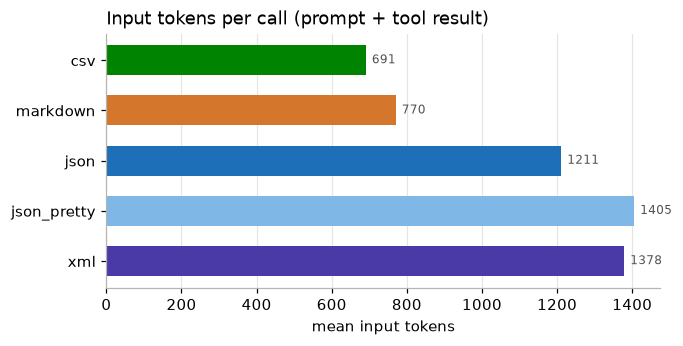

,mean input tokens,× csv,extra tokens per row vs csv
data_format,,,
csv,690.67,1.00,0.00
markdown,770.33,1.11,3.98
json,1210.83,1.75,26.01
json_pretty,1405.00,2.03,35.72
xml,1378.50,1.99,34.39


In [3]:
input_means = responses.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()[DATA_FORMATS]
input_table = pd.DataFrame({
    "mean input tokens": input_means.mean(),
    "× csv": (input_means.div(input_means["csv"], axis=0)).mean(),
    "extra tokens per row vs csv": (input_means.sub(input_means["csv"], axis=0) / 20).mean(),
}).round(2)

fig, ax = plt.subplots(figsize=(6.5, 3))
y = np.arange(len(DATA_FORMATS))
ax.barh(y, input_table["mean input tokens"], color=[DATA_COLORS[d] for d in DATA_FORMATS], height=0.6)
for i, v in enumerate(input_table["mean input tokens"]):
    ax.annotate(f"{v:.0f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, DATA_FORMATS)
ax.invert_yaxis()
ax.set_xlabel("mean input tokens")
ax.set_title("Input tokens per call (prompt + tool result)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()
input_table

## 2. Output tokens by format

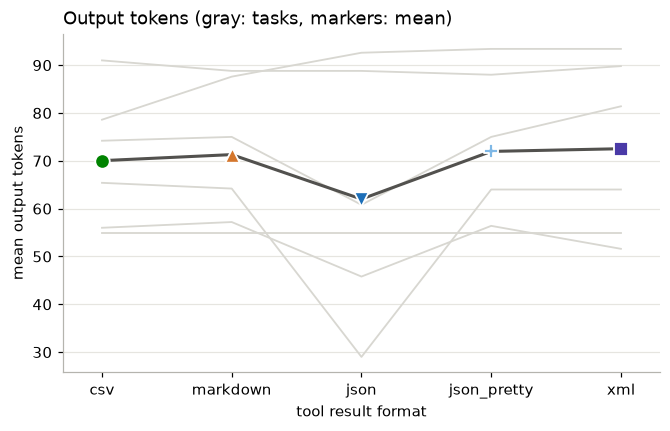

,mean,median
data_format,,
csv,70.0,70.0
markdown,71.0,70.0
json,62.0,57.0
json_pretty,72.0,70.0
xml,73.0,72.0


In [4]:
per_task = responses.groupby(["task_id", "data_format"])["output_tokens"].mean().unstack()[DATA_FORMATS]
x = np.arange(len(DATA_FORMATS))

fig, ax = plt.subplots(figsize=(7, 4))
for task_id, row in per_task.iterrows():
    ax.plot(x, row.values, color="#d8d7d1", linewidth=1.2, zorder=1)
ax.plot(x, per_task.mean().values, color="#52514e", linewidth=2, zorder=2)
for i, d in enumerate(DATA_FORMATS):
    ax.scatter(i, per_task[d].mean(), s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
               edgecolor="white", linewidth=1.2)
ax.set_xticks(x, DATA_FORMATS)
ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
ax.set_xlabel("tool result format")
ax.set_ylabel("mean output tokens")
ax.set_title("Output tokens (gray: tasks, markers: mean)", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

responses.groupby("data_format")["output_tokens"].agg(["mean", "median"]).round(0).loc[DATA_FORMATS]

## 3. Accuracy by format

Share of the 90 answers per format (6 tasks × 3 questions × 5 runs) that were correct, with 95% Wilson intervals.

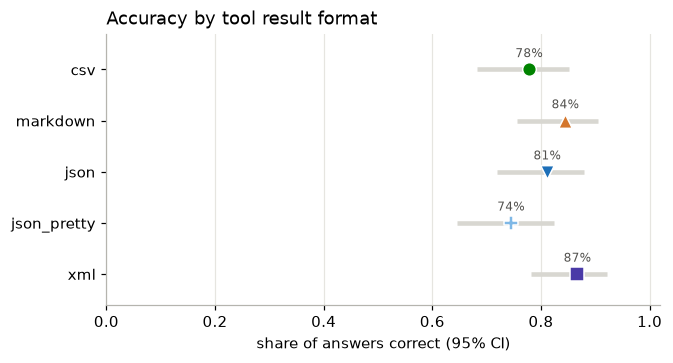

chi-square p (accuracy depends on format): 0.226


,n,correct,rate,low,high,all 3 correct
data_format,,,,,,
csv,90,70,0.778,0.682,0.851,0.333
markdown,90,76,0.844,0.756,0.905,0.533
json,90,73,0.811,0.718,0.879,0.533
json_pretty,90,67,0.744,0.646,0.823,0.400
xml,90,78,0.867,0.781,0.922,0.600


In [5]:
def wilson(k, n, z=1.96):
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half

accuracy = answers.groupby("data_format")["correct"].agg(n="size", correct="sum").loc[DATA_FORMATS]
accuracy["rate"] = accuracy["correct"] / accuracy["n"]
accuracy["low"], accuracy["high"] = wilson(accuracy["correct"], accuracy["n"])
accuracy["all 3 correct"] = responses.groupby("data_format")["n_correct"].apply(lambda s: (s == 3).mean())

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, d in enumerate(DATA_FORMATS):
    r = accuracy.loc[d]
    ax.hlines(i, r["low"], r["high"], color="#d8d7d1", linewidth=3, zorder=1)
    ax.scatter(r["rate"], i, s=80, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=2,
               edgecolor="white", linewidth=1)
    ax.annotate(f"{r['rate']:.0%}", (r["rate"], i), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(DATA_FORMATS)), DATA_FORMATS)
ax.set_ylim(len(DATA_FORMATS) - 0.4, -0.7)
ax.set_xlim(0, 1.02)
ax.set_xlabel("share of answers correct (95% CI)")
ax.set_title("Accuracy by tool result format", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

chi_p = stats.chi2_contingency(pd.crosstab(answers["data_format"], answers["correct"]))[1]
print(f"chi-square p (accuracy depends on format): {chi_p:.3f}")
accuracy.round(3)

## 4. Accuracy vs tokens

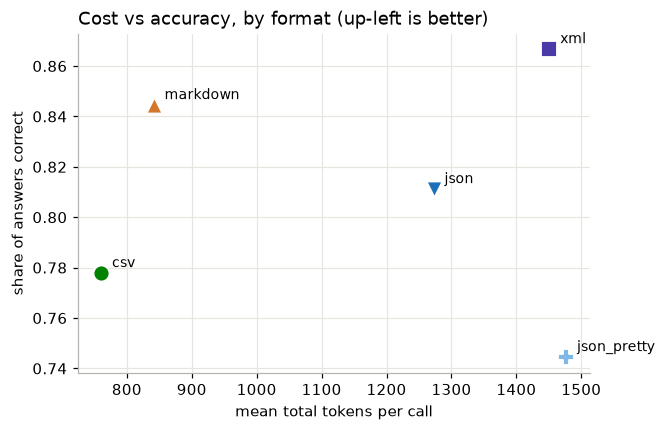

,mean total tokens,accuracy,tokens per correct answer
data_format,,,
csv,760.70,0.78,326.01
markdown,841.63,0.84,332.22
json,1272.83,0.81,523.08
json_pretty,1476.97,0.74,661.33
xml,1451.03,0.87,558.09


In [6]:
tradeoff = pd.DataFrame({
    "mean total tokens": responses.groupby("data_format")["total_tokens"].mean(),
    "accuracy": accuracy["rate"],
}).loc[DATA_FORMATS]
tradeoff["tokens per correct answer"] = (responses.groupby("data_format")["total_tokens"].sum()
                                         / accuracy["correct"]).loc[DATA_FORMATS]

fig, ax = plt.subplots(figsize=(6, 4))
for d in DATA_FORMATS:
    r = tradeoff.loc[d]
    ax.scatter(r["mean total tokens"], r["accuracy"], s=110, color=DATA_COLORS[d], marker=DATA_MARKERS[d],
               edgecolor="white", linewidth=1.2, zorder=2)
    ax.annotate(d, (r["mean total tokens"], r["accuracy"]), xytext=(7, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("mean total tokens per call")
ax.set_ylabel("share of answers correct")
ax.set_title("Cost vs accuracy, by format (up-left is better)", loc="left")
plt.show()
tradeoff.round(2)

## 5. Accuracy by task and question

In [7]:
by_question = answers.pivot_table(index=["task_id", "question"], columns="data_format",
                                  values="correct", aggfunc="mean")[DATA_FORMATS]
question_text = {(t, f"q{i}"): line.split(". ", 1)[1]
                 for t in TASK_IDS
                 for i, line in enumerate([l for l in read_task_file(t, "questions.txt").splitlines()
                                           if l[:2] in ("1.", "2.", "3.")], start=1)}
by_question.insert(0, "question text", [question_text[i] for i in by_question.index])
by_question.style.format("{:.0%}", subset=DATA_FORMATS).background_gradient(
    cmap="Greens", vmin=0, vmax=1, subset=DATA_FORMATS)

## Summary

- **Input:** markdown costs about 11% more than CSV (≈4 tokens per row); compact JSON 1.75×, pretty JSON and XML about 2× (26–36 extra tokens per row).
- **Output:** 60–75 tokens in every format; the format barely changes the answer.
- **Accuracy:** 74–87% in every format, no clear difference (chi-square p = 0.23). XML highest (87%), pretty JSON lowest (74%).
- **By question:** single-row lookups are 100% in every format, names from one row 83–100%; counting rows is where it breaks (40–70%).
- **Tokens per correct answer:** CSV and markdown ≈ 330, JSON ≈ 520, XML ≈ 560, pretty JSON ≈ 660. Markdown is the best trade-off: close to CSV's cost, among the most accurate.
- **Limits:** one 8B model, 6 tasks, 5 runs; most of the variation is between tasks (two tasks are 3/3 in every format), so gaps of a few points aren't reliable.